# P10 — Subconjunto Treg: resolução, estados (naive, ativada, eTreg) e marcadores de origem (tTreg, pTreg)

**Células.** As Treg da `anotacao` dentro das CD4 limpas do P09.

**Passos.**
1. Refaz HVG, ComBat, PCA, grafo e UMAP só nas Treg, com a receita do P09
   ([functions/subset.py](../functions/subset.py)).
2. Varre a resolução do Leiden (5 sementes). A regra é fixada antes de olhar os nomes: maior ARI
   médio entre sementes, entre as resoluções com ≥ 3 clusters. São 3 porque a referência de NMF
   (atlas de Yasumizu et al. 2024) divide a Treg em três: TregNaive, TregAct e TregEff.
3. Compara os clusters com as duas referências de NMF:
   - o atlas L2 (TregNaive, TregAct, TregEff);
   - a NMF k = 14 da 1ª rodada ("Treg" e "Treg efetora (HLA-DR⁺)").
4. Nomeia cada cluster misturando as duas fontes, clusters e NMF. O cluster dá a partição; o
   nome vem da posição no eixo naive → efetora, medida por três coisas: o atlas, a NMF e os
   marcadores.
5. Aplica os marcadores do consenso de nomenclatura (Masopust et al. 2026): eTreg pelos critérios
   humanos; tTreg × pTreg pelos critérios de camundongo, como exploração por célula. O consenso diz
   que não há marcadores estabelecidos para separar tTreg de pTreg em humanos.

**Saída.** A coluna `anotacaoSubset`:
- nas Treg, o nome do estado;
- nas demais CD4, a `anotacao` (o P11 refina naive e memória).

**Limites.**
- Em humanos não há marcador seguro de Treg tímica × periférica no RNA. O Helios é o critério
  mais usado (Thornton et al. 2010), mas é discutido.
- Nas bibliotecas estimuladas, T convencionais ativadas expressam FOXP3 de forma transitória.
- 7 pacientes; MB e NP com um paciente cada.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from IPython.display import display
from scipy.stats import fisher_exact

from functions import config, fmt as F, io, plotting
from functions import anotacao as an
from functions import subset as SB
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
sc.settings.verbosity = 0
plt.rcParams["savefig.bbox"] = "tight"

NB = "P10_treg_subset"
log = IssueLog(NB)
INK = plotting.INK
RES = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.2, 1.5]
SEEDS = (0, 1, 2, 3, 4)
MIN_CLUSTERS = 3
ESTADOS = ["Treg naive", "Treg ativada", "eTreg"]
ATLAS_TREG = {"TregNaive": 0.0, "TregAct": 0.5, "TregEff": 1.0}
NMF_TREG = {"Treg": 0.0, "Treg efetora (HLA-DR⁺)": 1.0}
PAINEL_NAIVE = ["CCR7", "SELL", "LEF1", "TCF7", "SATB1", "IL7R"]
PAINEL_EFETORA = ["HLA-DRA", "HLA-DRB1", "CD74", "ENTPD1", "LGALS3", "CCR4", "FANK1", "CTLA4", "LAYN", "CCR8"]
MARC_DOT = ["FOXP3", "IKZF2", "RTKN2", "IL2RA", "IKZF4", "CCR7", "SELL", "LEF1", "TCF7", "SATB1", "IL7R",
            "TNFRSF4", "TNFRSF18", "ICOS", "TIGIT", "CTLA4", "HLA-DRA", "CD74", "ENTPD1", "LGALS3", "CCR4", "FANK1",
            "LAYN", "CCR8", "IRF4", "PRDM1", "RORC", "GATA3", "MKI67"]

In [2]:
cd4 = SB.carregar_cd4()
N_CD4 = cd4.n_obs
tr = cd4[cd4.obs["anotacao"] == "Treg"].copy()
print(f"CD4 limpas: {F.n(N_CD4)}; Treg: {F.n(tr.n_obs)} ({F.pct(tr.n_obs / N_CD4, 1)})")
n_lib = tr.obs["library_id"].astype(str).value_counts().reindex(config.LIBRARIES)
display(n_lib.to_frame("Treg").T)

CD4 limpas: 30.933; Treg: 1.733 (5,6%)


library_id,CTH92_NS,CTH92_ML,CTH94_NS,CTH94_ML,CTH97_NS,CTH97_ML,PB20_NS,PB20_ML,PB21_NS,PB21_ML,MB34_NS,MB34_ML,HNP44_NS,HNP44_ML
Treg,38,48,281,32,53,61,15,38,221,653,115,62,5,111


## 1. Reprocessamento só nas Treg

In [3]:
b, info = SB.reprocessar(tr)
print(f"HVG: {len(info['hvg'])}; bibliotecas fora da escolha das HVG (< 20 Treg): {info['bibliotecas_fora_das_hvg']}; "
      f"variância nas {info['n_pcs']} PCs: {F.pct(info['variancia_pca'], 0)}")

HVG: 2000; bibliotecas fora da escolha das HVG (< 20 Treg): {'PB20_NS': 15, 'HNP44_NS': 5}; variância nas 30 PCs: 12%


## 2. Resolução

Para cada resolução:
- ARI médio e mínimo entre os 10 pares de sementes;
- fração de células em clusters estáveis (Jaccard ≥ 0,75);
- ARI da semente 0 com cada referência de NMF.

In [4]:
refs = {"atlas L2": b.obs["atlas_L2"].where(b.obs["atlas_L2"].isin(list(ATLAS_TREG))),
        "NMF k=14": b.obs["nmf14_rotulo"].where(b.obs["nmf14_rotulo"].isin(list(NMF_TREG)))}
sw, estab = SB.varrer(b, RES, seeds=SEEDS, referencias=refs)
cand = estab[estab["clusters"] >= MIN_CLUSTERS]
RES_FINAL = float(cand["ARI entre sementes (média)"].idxmax())
io.save_table(estab, NB, "estabilidade_por_resolucao", description="Treg: clusters, estabilidade entre sementes e ARI com a NMF")
print(f"resolução escolhida: {F.f(RES_FINAL, 1)} ({estab.loc[RES_FINAL, 'clusters']} clusters, ARI entre sementes "
      f"{F.f(estab.loc[RES_FINAL, 'ARI entre sementes (média)'], 2)})")
display(estab.round(3))

resolução escolhida: 0,4 (3 clusters, ARI entre sementes 0,72)


,clusters,clusters por semente,ARI entre sementes (média),ARI entre sementes (mínimo),células em clusters estáveis,menor cluster,ARI com atlas L2,ARI com NMF k=14
resolução,,,,,,,,
0.1,1,1 / 1 / 1 / 1 / 1,1.000,1.000,1.000,1733,0.000,0.000
0.2,2,2 / 2 / 2 / 2 / 2,0.719,0.471,1.000,598,0.400,0.328
0.3,3,3 / 2 / 4 / 3 / 2,0.535,0.314,0.343,475,0.270,0.269
0.4,3,3 / 4 / 4 / 4 / 4,0.721,0.595,1.000,429,0.290,0.263
0.5,4,4 / 3 / 6 / 4 / 4,0.660,0.514,0.744,6,0.298,0.256
0.6,5,5 / 5 / 5 / 5 / 6,0.612,0.408,0.649,6,0.219,0.222
0.8,8,8 / 7 / 8 / 7 / 8,0.546,0.454,0.187,6,0.230,0.181
1.0,10,10 / 9 / 10 / 10 / 9,0.546,0.442,0.237,6,0.174,0.139
1.2,12,12 / 10 / 11 / 12 / 13,0.544,0.438,0.062,6,0.160,0.141


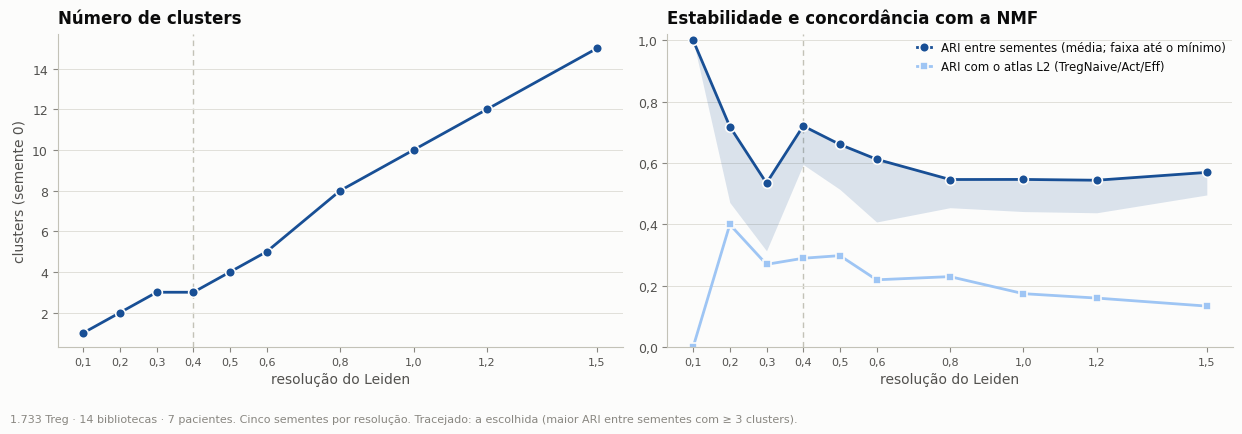

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.2))
cor = plotting.OLD_NEW_COLORS["nova"]
a1.plot(RES, estab["clusters"], "-o", color=cor, lw=2, ms=7, mec=INK["surface"], mew=1.2)
a1.set_ylabel("clusters (semente 0)")
a1.set_title("Número de clusters", loc="left")
a2.fill_between(RES, estab["ARI entre sementes (mínimo)"], estab["ARI entre sementes (média)"], color=cor, alpha=0.15, lw=0)
a2.plot(RES, estab["ARI entre sementes (média)"], "-o", color=cor, lw=2, ms=7, mec=INK["surface"], mew=1.2,
        label="ARI entre sementes (média; faixa até o mínimo)")
a2.plot(RES, estab["ARI com atlas L2"], "-s", color=plotting.OLD_NEW_COLORS["antiga"], lw=2, ms=6, mec=INK["surface"],
        mew=1.2, label="ARI com o atlas L2 (TregNaive/Act/Eff)")
a2.set_ylim(0, 1.02)
a2.set_title("Estabilidade e concordância com a NMF", loc="left")
a2.legend(loc="upper right", frameon=False, fontsize=8.5)
for ax in (a1, a2):
    ax.axvline(RES_FINAL, color=INK["axis"], lw=1, ls=(0, (4, 3)), zorder=0)
    ax.set_xlabel("resolução do Leiden")
    ax.set_xticks(RES)
    ax.set_xticklabels([F.f(r, 1) for r in RES], fontsize=8)
plotting.decimals(a2, "y", 1)
plotting.note(fig, f"{F.n(b.n_obs)} Treg · {plotting.N_DESIGN}. Cinco sementes por resolução. Tracejado: a escolhida "
                   f"(maior ARI entre sementes com ≥ {MIN_CLUSTERS} clusters).", y=0.0)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plotting.savefig(fig, NB, "resolucao", description="Treg: clusters e estabilidade por resolução",
                 data=estab.reset_index(), data_index=False)
plt.show()

## 3. Os clusters × a NMF e os marcadores

In [6]:
cl = sw[f"leiden_r{RES_FINAL:g}_s0"].astype(str).to_numpy()
b.obs["cluster"] = pd.Categorical(cl, categories=sorted(set(cl), key=int))
CL = list(b.obs["cluster"].cat.categories)
comp_at = SB.composicao(cl, b.obs["atlas_L2"]).reindex(columns=list(ATLAS_TREG), fill_value=0)
comp_nmf = SB.composicao(cl, b.obs["nmf14_rotulo"]).reindex(columns=list(NMF_TREG), fill_value=0)
C = (sp.csr_matrix(b[:, [g for g in MARC_DOT if g in b.var_names]].layers["counts"]) > 0).toarray()
det = pd.DataFrame(C, columns=[g for g in MARC_DOT if g in b.var_names]).groupby(cl).mean().reindex(CL)
esc = SB.escores(b, {"naive": PAINEL_NAIVE, "efetora": PAINEL_EFETORA}, cl).reindex(CL)
z = (esc - esc.mean()) / esc.std(ddof=0)

# eixo naive → efetora: média de três fontes, cada uma levada a 0–1 entre os clusters
at_cel = b.obs["atlas_L2"].map(ATLAS_TREG).astype(float)
nmf_cel = b.obs["nmf14_rotulo"].map(NMF_TREG).astype(float)
fontes = pd.DataFrame({"atlas L2": at_cel.groupby(cl).mean(), "NMF k=14": nmf_cel.groupby(cl).mean(),
                       "marcadores": esc["efetora"] - esc["naive"]}).reindex(CL)
fontes01 = (fontes - fontes.min()) / (fontes.max() - fontes.min()).replace(0, 1)
eixo = fontes01.mean(axis=1)
tab = pd.concat([pd.Series(cl).value_counts().reindex(CL).rename("células"),
                 pd.Series(b.obs["estimulo"].astype(str).to_numpy() == "estimulado").groupby(cl).mean().reindex(CL).rename("fração ML"),
                 comp_at.add_prefix("atlas "), comp_nmf.add_prefix("NMF "), fontes01.add_prefix("eixo · "),
                 eixo.rename("eixo naive→efetora (média)")], axis=1)
io.save_table(tab, NB, "clusters_x_nmf", description="Clusters Treg: composição pelo atlas L2 e pela NMF k=14, e o eixo naive→efetora")
display(tab.round(2))
display(det.T.round(2))

,células,fração ML,atlas TregNaive,atlas TregAct,atlas TregEff,NMF Treg,NMF Treg efetora (HLA-DR⁺),eixo · atlas L2,eixo · NMF k=14,eixo · marcadores,eixo naive→efetora (média)
0,735,0.60,0.02,0.17,0.62,0.24,0.64,1.00,1.00,1.00,1.00
1,569,0.56,0.39,0.37,0.01,0.83,0.01,0.00,0.00,0.00,0.00
2,429,0.57,0.09,0.23,0.41,0.38,0.49,0.75,0.77,0.71,0.74


,0,1,2
FOXP3,0.86,0.77,0.70
IKZF2,0.84,0.79,0.67
RTKN2,0.71,0.80,0.69
IL2RA,0.78,0.71,0.62
IKZF4,0.33,0.34,0.22
CCR7,0.42,0.76,0.41
SELL,0.78,0.85,0.73
LEF1,0.67,0.92,0.64
TCF7,0.24,0.62,0.29
SATB1,0.26,0.46,0.24


**Regra dos nomes** (mistura das duas fontes):
- o cluster de menor eixo é **Treg naive**; o de maior eixo é **eTreg** (efetora);
- os do meio são **Treg ativada**, o estado intermediário (o TregAct do atlas).

**Concordância das fontes.** As três fontes ordenam os clusters do mesmo jeito? A tabela acima
mostra cada uma (0–1).

In [7]:
nome = pd.Series("Treg ativada", index=CL)
nome[eixo.idxmin()], nome[eixo.idxmax()] = "Treg naive", "eTreg"
concordam = fontes01.rank().corr(method="spearman")
print("ordem dos clusters no eixo:", " < ".join(f"{c} ({nome[c]})" for c in eixo.sort_values().index))
display(concordam.round(2))

ordem dos clusters no eixo: 1 (Treg naive) < 2 (Treg ativada) < 0 (eTreg)


,atlas L2,NMF k=14,marcadores
atlas L2,1.0,1.0,1.0
NMF k=14,1.0,1.0,1.0
marcadores,1.0,1.0,1.0


## 4. Marcadores do consenso de nomenclatura: eTreg, tTreg e pTreg

Referência: Masopust et al. 2026, "Guidelines for T cell nomenclature", *Nat Rev Immunol*
26:298–313, Tabela 3.

| célula | humano | camundongo |
| --- | --- | --- |
| Treg | FOXP3⁺, CD25hi, CD127low, CTLA4⁺, GITR⁺ | igual |
| tTreg | FOXP3⁺, CCR7hi, CD45RA⁺, CD45RO⁻ | FOXP3⁺, CD62L⁺, CD44lo, neuropilina-1hi, Helios hi |
| pTreg | FOXP3⁺, CCR7hi, CD45RA⁺, CD45RO⁻ | FOXP3⁺, CD62L⁺, CD44lo, neuropilina-1lo, RORγt⁺ ou GATA3hi, Helios low/int |
| eTreg | FOXP3hi, CD45RO⁺, CCR8hi, ICOShi, IRF4⁺ | FOXP3hi, BLIMP1⁺, IL-10⁺, TGFβ⁺ |

O texto do consenso diz: "*Currently, there are no established markers to distinguish tTreg and
pTreg cells in humans*". Os critérios humanos de tTreg e de pTreg são os mesmos (fenótipo naive).

**No RNA.** As proteínas viram genes: CD25 = IL2RA, CD127 = IL7R, GITR = TNFRSF18, CD62L = SELL,
RORγt = RORC, neuropilina-1 = NRP1, BLIMP1 = PRDM1. CD45RA/RO são isoformas de PTPRC, que o 3′
não separa. Por isso, CCR7 e SELL fazem o papel de naive.

**Como se aplica.**
- **eTreg** e **Treg naive:** critérios humanos, por cluster. A média escalonada (z entre os
  clusters) de cada conjunto de genes tem de ser máxima no cluster que recebeu o nome.
- **tTreg × pTreg:** só os critérios de camundongo existem. Aqui eles entram como **exploração
  por célula**, sem virar nome de cluster:
  - **Helios⁺** (perfil tTreg de camundongo): FOXP3 e IKZF2 detectados;
  - **Helios⁻ com RORC ou GATA3 alto** (perfil pTreg de camundongo): FOXP3 detectado, IKZF2 não
    detectado, e RORC detectado ou GATA3 acima do quartil superior das Treg;
  - o NRP1 não serve: quase não se expressa na Treg humana do sangue.

In [8]:
CONS_GENES = ["FOXP3", "IL2RA", "CTLA4", "TNFRSF18", "IL7R", "CCR7", "SELL", "CCR8", "ICOS", "IRF4", "PRDM1",
              "IKZF2", "NRP1", "RORC", "GATA3"]
CONS_GENES = [g for g in CONS_GENES if g in b.var_names]
Xl = b[:, CONS_GENES].X
Xl = Xl.toarray() if sp.issparse(Xl) else np.asarray(Xl)
Cl = (sp.csr_matrix(b[:, CONS_GENES].layers["counts"]) > 0).toarray()
media = pd.DataFrame(Xl, columns=CONS_GENES).groupby(cl).mean().reindex(CL)
detec = pd.DataFrame(Cl, columns=CONS_GENES).groupby(cl).mean().reindex(CL)
zc = (media - media.mean()) / media.std(ddof=0).replace(0, 1)
CRIT = {"eTreg (humano): FOXP3hi CCR8hi ICOShi IRF4⁺": ["FOXP3", "CCR8", "ICOS", "IRF4"],
        "Treg naive (humano): CCR7hi, CD62L (SELL)": ["CCR7", "SELL"]}
crit = pd.DataFrame({k: zc[[g for g in v if g in zc]].mean(axis=1) for k, v in CRIT.items()})
crit["estado"] = nome
confere_cons = {"eTreg": crit.iloc[:, 0].idxmax() == nome[nome == "eTreg"].index[0],
                "Treg naive": crit.iloc[:, 1].idxmax() == nome[nome == "Treg naive"].index[0]}
io.save_table(pd.concat([detec.add_prefix("detecção "), media.add_prefix("média ")], axis=1), NB, "consenso_marcadores_por_cluster",
              description="Treg: marcadores do consenso (Masopust et al. 2026), detecção e média da lognorm por cluster")
io.save_table(crit, NB, "consenso_criterios_por_cluster", description="Treg: escore z dos critérios humanos de eTreg e Treg naive por cluster")
display(detec.T.round(2))
display(crit.round(2))
print("o critério humano do consenso aponta o mesmo cluster que o nome:", confere_cons)

# exploração por célula com os critérios de camundongo (tTreg × pTreg)
g = {x: CONS_GENES.index(x) for x in CONS_GENES}
fox, hel_c = Cl[:, g["FOXP3"]], Cl[:, g["IKZF2"]]
gata_alto = Xl[:, g["GATA3"]] > np.quantile(Xl[:, g["GATA3"]], 0.75)
rorc = Cl[:, g["RORC"]]
origem = np.select([fox & hel_c, fox & ~hel_c & (rorc | gata_alto), fox & ~hel_c],
                   ["Helios⁺ (perfil tTreg de camundongo)", "Helios⁻ RORC⁺/GATA3hi (perfil pTreg de camundongo)",
                    "Helios⁻ sem RORC/GATA3"], "FOXP3 não detectado")
b.obs["origem_criterio_camundongo"] = origem
orig_cel = pd.crosstab(pd.Series(cl, name="cluster").map(lambda c: f"{c} · {nome[c]}"), pd.Series(origem, name="origem"),
                       normalize="index")
io.save_table(orig_cel, NB, "origem_criterio_camundongo", description="Treg: fração de células com perfil tTreg/pTreg de camundongo, por cluster")
display(orig_cel.round(3))
print(f"NRP1 detectado em {F.pct(detec['NRP1'].max(), 1)} das células, no máximo, entre os clusters" if "NRP1" in detec else "NRP1 ausente")

hel = pd.Series(C[:, list(det.columns).index("IKZF2")], index=b.obs_names)
linhas = []
for c in CL:
    m = cl == c
    tt = [[int(hel[m].sum()), int((~hel[m]).sum())], [int(hel[~m].sum()), int((~hel[~m]).sum())]]
    orr, p = fisher_exact(tt)
    linhas.append({"cluster": c, "estado": nome[c], "células": int(m.sum()), "Helios detectado": float(hel[m].mean()),
                   "FOXP3 detectado": float(det.loc[c, "FOXP3"]), "OR (vs demais)": orr, "p": p})
orig = pd.DataFrame(linhas).set_index("cluster")
orig["FDR"] = np.minimum(1, orig["p"] * len(orig) / orig["p"].rank())
io.save_table(orig, NB, "helios_por_cluster", description="Helios (IKZF2) por cluster Treg e teste contra os demais")
display(orig.round(3))

# sem marcador humano de origem (consenso), o nome do cluster é só o estado
final = nome.copy()
b.obs["anotacaoSubset"] = pd.Categorical(final.reindex(cl).to_numpy())
print(final.to_dict())

,0,1,2
FOXP3,0.86,0.77,0.70
IL2RA,0.78,0.71,0.62
CTLA4,0.75,0.55,0.49
TNFRSF18,0.32,0.07,0.22
IL7R,0.50,0.65,0.50
CCR7,0.42,0.76,0.41
SELL,0.78,0.85,0.73
CCR8,0.09,0.00,0.03
ICOS,0.73,0.64,0.51
IRF4,0.28,0.17,0.14


,eTreg (humano): FOXP3hi CCR8hi ICOShi IRF4⁺,"Treg naive (humano): CCR7hi, CD62L (SELL)",estado
0,1.34,-1.00,eTreg
1,-0.87,1.34,Treg naive
2,-0.47,-0.33,Treg ativada


o critério humano do consenso aponta o mesmo cluster que o nome: {'eTreg': True, 'Treg naive': True}


origem,FOXP3 não detectado,Helios⁺ (perfil tTreg de camundongo),Helios⁻ RORC⁺/GATA3hi (perfil pTreg de camundongo),Helios⁻ sem RORC/GATA3
cluster,,,,
0 · eTreg,0.144,0.716,0.041,0.099
1 · Treg naive,0.227,0.634,0.007,0.132
2 · Treg ativada,0.301,0.490,0.058,0.152


NRP1 detectado em 0,4% das células, no máximo, entre os clusters


,estado,células,Helios detectado,FOXP3 detectado,OR (vs demais),p,FDR
cluster,,,,,,,
0,eTreg,735,0.838,0.856,1.843,0.000,0.000
1,Treg naive,569,0.791,0.773,1.098,0.459,0.459
2,Treg ativada,429,0.667,0.699,0.447,0.000,0.000


{'0': 'eTreg', '1': 'Treg naive', '2': 'Treg ativada'}


**FOXP3⁺ Helios⁻ fora do cluster Treg.** As pTreg e as T convencionais ativadas com FOXP3
transitório ficariam fora do cluster Treg. A tabela conta, por `anotacao` e estímulo, as CD4 com
FOXP3 detectado e sem IKZF2. Não há como distinguir os dois casos aqui, e por isso essas células
**não** recebem rótulo.

In [9]:
gi = [list(cd4.var_names).index(g) for g in ["FOXP3", "IKZF2"]]
Cc = (sp.csr_matrix(cd4.layers["counts"][:, gi]) > 0).toarray()
fora = cd4.obs["anotacao"].astype(str).to_numpy() != "Treg"
cand_p = fora & Cc[:, 0] & ~Cc[:, 1]
tp = pd.crosstab(cd4.obs.loc[cand_p, "anotacao"].astype(str), cd4.obs.loc[cand_p, "estimulo"].astype(str))
tp["total"] = tp.sum(axis=1)
tp = tp.sort_values("total", ascending=False)
io.save_table(tp, NB, "foxp3_helios_neg_fora_treg", description="CD4 fora do cluster Treg com FOXP3 detectado e IKZF2 não detectado")
print(f"{F.n(cand_p.sum())} células FOXP3⁺ IKZF2⁻ fora do cluster Treg ({F.pct(cand_p.sum() / fora.sum(), 1)} das CD4 não Treg)")
display(tp)

974 células FOXP3⁺ IKZF2⁻ fora do cluster Treg (3,3% das CD4 não Treg)


estimulo,estimulado,nao estimulado,total
anotacao,,,
CD4 ativada,365,33,398
CD4 naive,123,53,176
CD4 Tcm/Tfh,65,37,102
CD4 transição naive/Tcm,72,27,99
CD4 ativada (Th17),61,5,66
CD4 Tcm,34,31,65
CD4 Th17,16,33,49
CD4 citotóxica (Temra),14,4,18
CD4 Tem GZMK⁺,1,0,1


## 5. Figuras

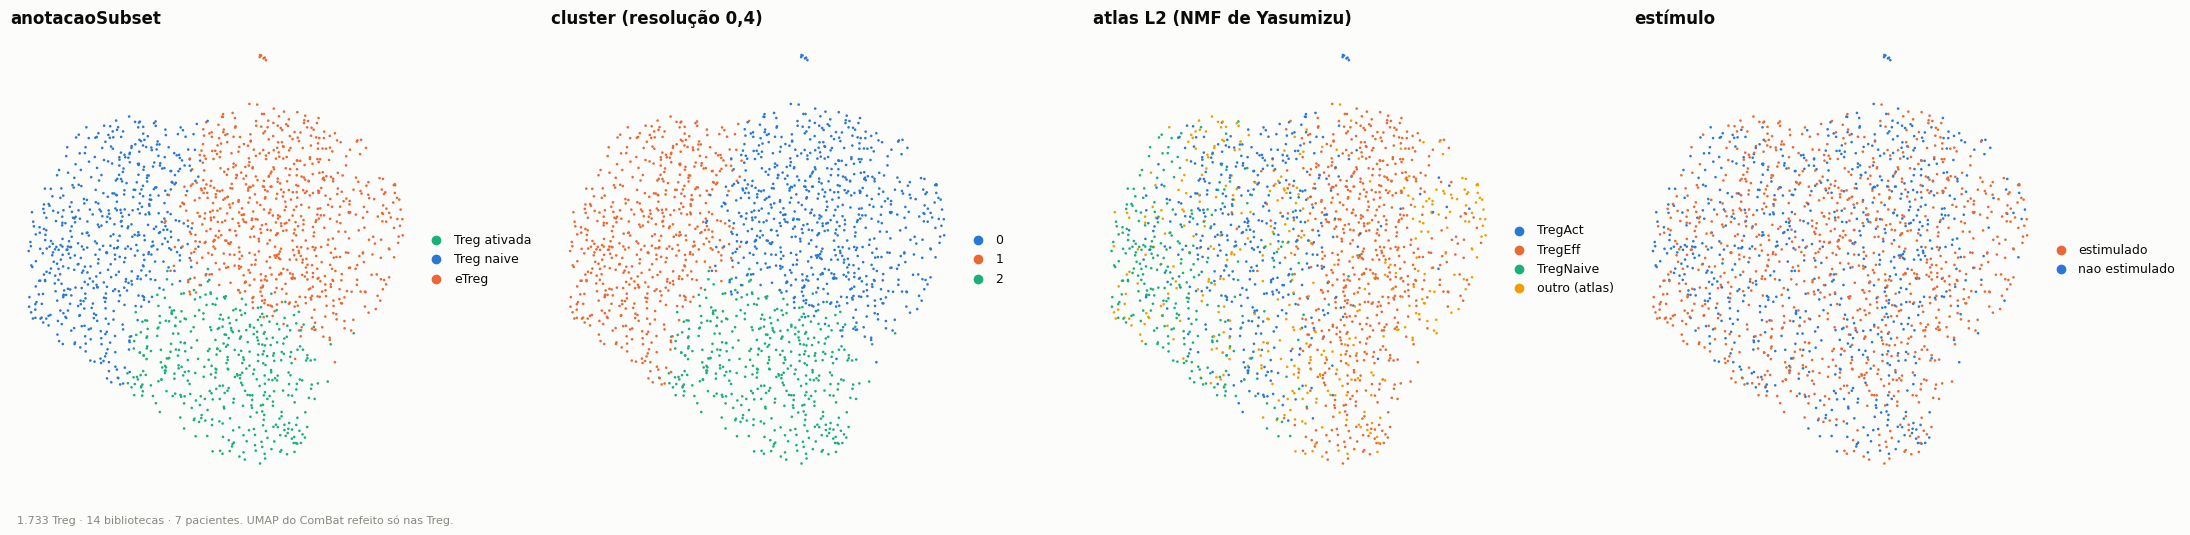

In [10]:
pal = {"Treg naive (tTreg)": plotting.CATEGORICAL[0], "Treg naive": plotting.CATEGORICAL[0],
       "Treg ativada": plotting.CATEGORICAL[2], "Treg ativada (pTreg?)": plotting.CATEGORICAL[2], "eTreg": plotting.CATEGORICAL[1]}
cats = list(b.obs["anotacaoSubset"].cat.categories)
b.uns["anotacaoSubset_colors"] = [pal.get(c, plotting.CATEGORICAL[3]) for c in cats]
b.obs["atlas_L2_treg"] = pd.Categorical(b.obs["atlas_L2"].where(b.obs["atlas_L2"].isin(list(ATLAS_TREG)), "outro (atlas)"))
b.obs["estimulo"] = pd.Categorical(b.obs["estimulo"].astype(str))
b.uns["estimulo_colors"] = [plotting.STIMULATION_COLORS["estimulado"] if c == "estimulado"
                            else plotting.STIMULATION_COLORS["nao_estimulado"] for c in b.obs["estimulo"].cat.categories]
fig, axes = plt.subplots(1, 4, figsize=(22, 5.2))
for ax, (col, tit) in zip(axes, [("anotacaoSubset", "anotacaoSubset"), ("cluster", f"cluster (resolução {F.f(RES_FINAL, 1)})"),
                                 ("atlas_L2_treg", "atlas L2 (NMF de Yasumizu)"), ("estimulo", "estímulo")]):
    sc.pl.umap(b, color=col, ax=ax, show=False, frameon=False, size=14, title=tit)
plotting.note(fig, f"{F.n(b.n_obs)} Treg · {plotting.N_DESIGN}. UMAP do ComBat refeito só nas Treg.", y=0.0)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plotting.savefig(fig, NB, "umap_treg", description="UMAP das Treg: estado final, cluster, atlas L2 e estímulo",
                 data=pd.DataFrame({"cell_key": b.obs["cell_key"].astype(str).to_numpy(), "cluster": cl,
                                    "anotacaoSubset": b.obs["anotacaoSubset"].astype(str).to_numpy(),
                                    "atlas_L2": b.obs["atlas_L2"].astype(str).to_numpy(),
                                    "umap1": b.obsm["X_umap"][:, 0], "umap2": b.obsm["X_umap"][:, 1]}), data_index=False)
plt.show()

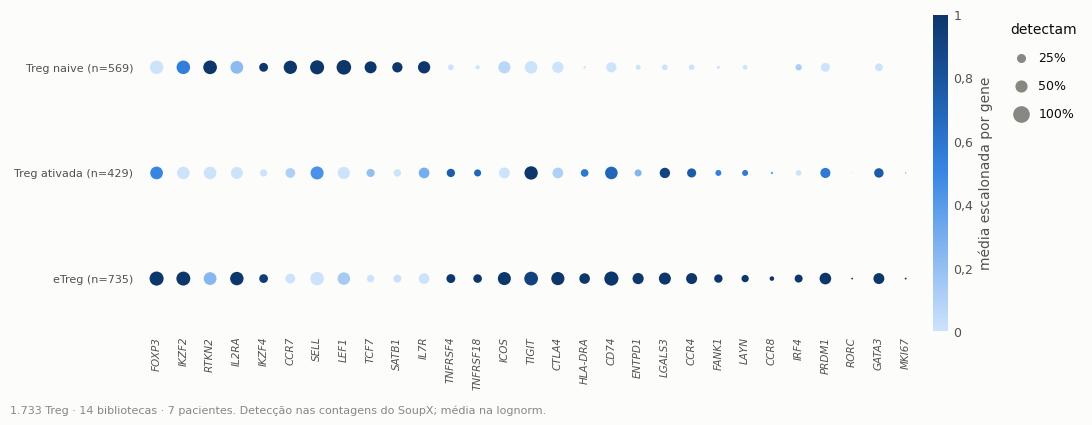

In [11]:
genes = [g for g in MARC_DOT if g in b.var_names]
ordem = [c for c in ["Treg naive (tTreg)", "Treg naive", "Treg ativada", "eTreg"] if c in cats] + \
        [c for c in cats if c not in ["Treg naive (tTreg)", "Treg naive", "Treg ativada", "eTreg"]]
frac, mean = an.dot_stats(b, b.obs["anotacaoSubset"], genes)
n_e = b.obs["anotacaoSubset"].astype(str).value_counts()
fig, ax = plt.subplots(figsize=(11, 0.5 * len(ordem) + 2.6))
sc_ = an.dotplot(ax, frac, mean, rows=ordem, cols=genes)
ax.set_yticklabels([f"{e} (n={F.n(n_e[e])})" for e in ordem])
cb = fig.colorbar(sc_, ax=ax, fraction=0.03, pad=0.01)
cb.set_label("média escalonada por gene")
plotting._style_colorbar(cb)
for v in (0.25, 0.5, 1.0):
    ax.scatter([], [], s=v * 120, c=INK["muted"], label=F.pct(v, 0))
ax.legend(title="detectam", loc="upper left", bbox_to_anchor=(1.1, 1.0), frameon=False, labelspacing=1.2)
plotting.note(fig, f"{F.n(b.n_obs)} Treg · {plotting.N_DESIGN}. Detecção nas contagens do SoupX; média na lognorm.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "dotplot_treg", description="Marcadores de Treg por estado final",
                 data=(frac * 100).round(1).reindex(ordem).rename_axis("anotacaoSubset").reset_index(), data_index=False)
plt.show()

In [12]:
por_lib = pd.crosstab(b.obs["library_id"].astype(str), b.obs["anotacaoSubset"].astype(str), normalize="index").reindex(config.LIBRARIES)
io.save_table(por_lib, NB, "estado_por_biblioteca", description="Fração de cada estado de Treg por biblioteca")
display(por_lib.round(2))

anotacaoSubset,Treg ativada,Treg naive,eTreg
library_id,,,
CTH92_NS,0.32,0.50,0.18
CTH92_ML,0.21,0.42,0.38
CTH94_NS,0.16,0.39,0.44
CTH94_ML,0.09,0.47,0.44
CTH97_NS,0.28,0.34,0.38
CTH97_ML,0.28,0.15,0.57
PB20_NS,0.47,0.33,0.20
PB20_ML,0.29,0.37,0.34
PB21_NS,0.33,0.27,0.40


## 6. Saídas

- `treg_subset.h5ad`: delta das Treg (cluster, `anotacaoSubset`, Helios detectado, embedding e UMAP).
- `anotacao_subset.parquet`: `anotacaoSubset` de todas as CD4 limpas. Nas Treg é o estado; nas
  demais, por enquanto, a `anotacao`.

In [13]:
out = ad.AnnData(X=sp.csr_matrix((b.n_obs, 0), dtype=np.float32),
                 obs=pd.DataFrame({"cell_key": b.obs["cell_key"].astype(str).to_numpy(), "cluster": cl,
                                   "anotacaoSubset": b.obs["anotacaoSubset"].astype(str).to_numpy(),
                                   "helios_detectado": hel.to_numpy(),
                                   "origem_criterio_camundongo": b.obs["origem_criterio_camundongo"].astype(str).to_numpy()},
                                  index=b.obs_names))
out.obsm["X_emb_combat"] = b.obsm["X_emb"]
out.obsm["X_umap"] = np.asarray(b.obsm["X_umap"], np.float32)
out.uns["treg_subset"] = {"resolucao": RES_FINAL, "hvg": info["hvg"], "nomes": final.to_dict()}
print(io.save_data(out, NB, "treg_subset", description="Delta do subconjunto Treg: cluster, estado, Helios, UMAP"))

sub = pd.DataFrame({"cell_key": cd4.obs["cell_key"].astype(str).to_numpy(), "anotacao": cd4.obs["anotacao"].astype(str).to_numpy()})
sub["anotacaoSubset"] = sub["anotacao"]
mapa = pd.Series(b.obs["anotacaoSubset"].astype(str).to_numpy(), index=b.obs["cell_key"].astype(str).to_numpy())
m = sub["cell_key"].isin(mapa.index)
sub.loc[m, "anotacaoSubset"] = mapa.reindex(sub.loc[m, "cell_key"]).to_numpy()
print(io.save_data(sub, NB, "anotacao_subset", description="anotacaoSubset das CD4 limpas: estados de Treg; demais = anotacao"))
display(sub["anotacaoSubset"].value_counts().to_frame())

[io] conteúdo mudou — nova versão: treg_subset__v3.h5ad (anterior preservada)
/mnt/SATA/singleCellTaru/dataReseq/P10_treg_subset/treg_subset__v3.h5ad
[io] conteúdo mudou — nova versão: anotacao_subset__v3.parquet (anterior preservada)
/mnt/SATA/singleCellTaru/dataReseq/P10_treg_subset/anotacao_subset__v3.parquet


,count
anotacaoSubset,
CD4 naive,11759
CD4 Tcm,4968
CD4 Tcm/Tfh,3086
CD4 ativada,2798
CD4 transição naive/Tcm,2696
CD4 Th17,2159
CD4 citotóxica (Temra),1321
eTreg,735
Treg naive,569


## 7. Interpretação

**Resolução.** A regra escolheu 0,4: 3 clusters, ARI entre sementes 0,72 e 100 % das células em
clusters estáveis. Acima disso a estabilidade cai (≤ 0,61).

**Estados.** Atlas, NMF k = 14 e marcadores ordenam os 3 clusters igualmente no eixo naive →
efetora.
- **Treg naive**, 569 células: CCR7, SELL, LEF1, TCF7 e SATB1 altos; HLA-DR quase ausente.
  Critério humano do consenso (CCR7hi, CD62L) com z 1,34, o maior.
- **eTreg**, 735 células: FOXP3 86 %, ICOS 73 %, IRF4 28 % e CCR8 9 %, todos os maiores entre
  os clusters. HLA-DR, CD39, CCR4 e PRDM1 (BLIMP1) também altos. Critério humano de eTreg do
  consenso (FOXP3hi, CCR8hi, ICOShi, IRF4⁺) com z 1,34, o maior.
- **Treg ativada**, 429 células: intermediária. É também a de identidade Treg mais fraca:
  FOXP3 70 %, Helios 67 % (OR 0,45 contra os demais, FDR < 0,001), IL2RA e CTLA4 os menores.

**tTreg × pTreg.** O consenso diz que não há marcadores humanos estabelecidos: os critérios
humanos de tTreg e pTreg são os mesmos. Por isso nenhum cluster recebe tTreg ou pTreg no nome.
Pelos critérios de camundongo, aplicados por célula:
- **neuropilina-1 (NRP1)** não serve: está em ≤ 0,4 % das células;
- **Helios⁺** (perfil tTreg de camundongo): 72 % das eTreg, 63 % das naive e 49 % das ativadas;
- **Helios⁻ com RORC⁺ ou GATA3 alto** (perfil pTreg de camundongo): 4 %, 1 % e 6 %. O RORC quase
  não aparece (≤ 1 %), e o que pesa é o GATA3.

A Treg ativada concentra o perfil pTreg (6 %) e o Helios mais baixo. Isso é exploratório.

**Fora do cluster Treg** há 974 CD4 FOXP3⁺ Helios⁻, 77 % em ML. É o padrão de FOXP3 transitório
em T convencionais ativadas, que o RNA não separa de pTreg.

**Limites.** HNP44_NS tem 5 Treg e PB20_NS 15; as frações por biblioteca dessas duas são
instáveis.

## Problemas encontrados

In [14]:
log.add("MAJOR", "origem tTreg × pTreg", "não há marcador humano estabelecido de tTreg × pTreg (Masopust et al. 2026)",
        evidence=f"Helios detectado em {F.pct(orig['Helios detectado'].min(), 0)}–{F.pct(orig['Helios detectado'].max(), 0)} "
                 f"das células em todos os clusters; {F.n(cand_p.sum())} CD4 FOXP3⁺ IKZF2⁻ fora do cluster Treg",
        impact="tTreg e pTreg não viram nome de cluster; os critérios de camundongo ficam só por célula (origem_criterio_camundongo)",
        recommendation="validar por citometria (Helios, CD45RA, CD39) ou por TSDR antes de afirmar origem")
show(log.save())

severity,location,problem,evidence,impact,recommendation
MAJOR,origem tTreg × pTreg,não há marcador humano estabelecido de tTreg × pTreg (Masopust et al. 2026),Helios detectado em 67%–84% das células em todos os clusters; 974 CD4 FOXP3⁺ IKZF2⁻ fora do cluster Treg,tTreg e pTreg não viram nome de cluster; os critérios de camundongo ficam só por célula (origem_criterio_camundongo),"validar por citometria (Helios, CD45RA, CD39) ou por TSDR antes de afirmar origem"
